## Comparison of Adaboost-MLP v/s Adaboost with KAN
 - Dataset : Breast Cancer Dataset
 - No of Estimators: 5

# 1. Adaboost-MLP On Breast Cancer Dataset

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

In [ ]:
data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test  = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_test  = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

In [ ]:
class MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(30, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
class AdaBoostMLP:
    def __init__(self, n_estimators=5):
        self.n_estimators = n_estimators
        self.models = []
        self.alphas = []

    def fit(self):
        n = len(y_train)
        weights = torch.ones(n) / n

        for m in range(self.n_estimators):
            model = MLP()

            optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
            loss_fn = nn.BCEWithLogitsLoss(reduction="none")

            # Train
            for _ in range(50):
                model.train()
                logits = model(X_train)

                losses = loss_fn(logits, y_train)
                weighted_loss = (losses.squeeze() * weights).mean()

                optimizer.zero_grad()
                weighted_loss.backward()
                optimizer.step()

                # Predictions
                with torch.no_grad():
                    logits = model(X_train)
                    preds = (torch.sigmoid(logits) > 0.5).float()
                    incorrect = (preds != y_train).float().squeeze()

                err = torch.sum(weights * incorrect)

                # Avoid division instability
                err = torch.clamp(err, 1e-6, 1 - 1e-6)
                alpha = 0.5 * torch.log((1 - err) / err)

                weights *= torch.exp(alpha * incorrect)
                weights /= weights.sum()

                self.models.append(model)
                self.alphas.append(alpha)

    def predict_proba(self, X):
        logits_sum = 0
        for model, alpha in zip(self.models, self.alphas):
            logits_sum += alpha * model(X)
        return torch.sigmoid(logits_sum)

    def evaluate(self):
        with torch.no_grad():
            probs = self.predict_proba(X_test).numpy().ravel()
            y_true = y_test.numpy().ravel()

        auc_kan = roc_auc_score(y_true, probs)
        fpr, tpr, _ = roc_curve(y_true, probs)
        return auc_kan, fpr, tpr


In [ ]:
boosted_model = AdaBoostMLP(n_estimators=5)
boosted_model.fit()

auc_kan, fpr, tpr = boosted_model.evaluate()

print(f"AdaBoost MLP ROC-AUC: {auc_kan:.4f}")

AdaBoost MLP ROC-AUC: 0.9866


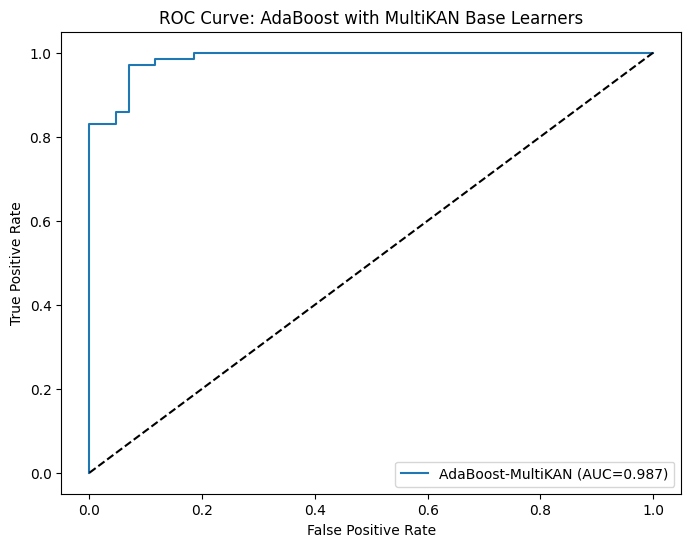

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AdaBoost-MultiKAN (AUC={auc_kan:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: AdaBoost with MultiKAN Base Learners")
plt.legend()
plt.show()

# 2. Adaboost with KAN On Breast Cancer Dataset

In [ ]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test  = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_test  = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

/tmp/ipykernel_4881/3787606413.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_train = torch.tensor(X_train, dtype=torch.float32)
/tmp/ipykernel_4881/3787606413.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_test  = torch.tensor(X_test, dtype=torch.float32)
/tmp/ipykernel_4881/3787606413.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
/tmp/ipykernel_4881/3787606413.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.det

In [ ]:
def b_spline_basis(x, knots, k):
    B = ((x[:, None] >= knots[:-1]) & (x[:, None] < knots[1:])).float()

    for d in range(1, k + 1):
        left_num = x[:, None] - knots[:-d-1]
        left_den = knots[d:-1] - knots[:-d-1]

        right_num = knots[d+1:] - x[:, None]
        right_den = knots[d+1:] - knots[1:-d]

        left = torch.where(left_den != 0, left_num / left_den, torch.zeros_like(left_den))
        right = torch.where(right_den != 0, right_num / right_den, torch.zeros_like(right_den))

        B = left * B[:, :-1] + right * B[:, 1:]

    return B

In [ ]:
class KANLayer(nn.Module):
    def __init__(self, in_dim, out_dim, num_knots, k=3):
        super().__init__()

        base_knots = torch.linspace(-1, 1, num_knots)
        h = base_knots[1] - base_knots[0]

        left_ext = base_knots[0] - h * torch.arange(k, 0, -1)
        right_ext = base_knots[-1] + h * torch.arange(1, k + 1)

        self.knots = torch.cat([left_ext, base_knots, right_ext])
        self.n_basis = len(self.knots) - k - 1

        self.coef = nn.Parameter(
            torch.randn(in_dim, out_dim, self.n_basis) * 0.1
        )

    def forward(self, x):
        B_all = []
        for i in range(x.shape[1]):
            B_i = b_spline_basis(x[:, i], self.knots, k=3)
            B_all.append(B_i)

        B = torch.stack(B_all, dim=1)
        y = torch.einsum('bik,ijk->bj', B, self.coef) # y = B @ self.coef


        return y

In [ ]:
class MultiKAN(nn.Module):
    def __init__(self, width, num_knots=8):
        super().__init__()
        self.layers = nn.ModuleList(
            [KANLayer(width[i], width[i+1], num_knots) for i in range(len(width)-1)]
        )

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

In [ ]:
losses_of_estimators=[]

In [ ]:
def train_weighted_multikan(sample_weights,m,epochs=50, lr=1e-3):
    model = MultiKAN(width=[30, 20, 1], num_knots=8)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss(reduction="none")
    estimator_loss=[m+1]
    for _ in range(epochs):
        model.train()
        logits = model(X_train)
        losses = loss_fn(logits, y_train)


        weighted_loss = (losses.squeeze() * sample_weights).mean()
        estimator_loss.append(weighted_loss.item())
        # print(weighted_loss.item())
        optimizer.zero_grad()
        weighted_loss.backward()
        optimizer.step()

    losses_of_estimators.append(estimator_loss)
    # print(losses_of_estimators)
    # estimator_loss.clear()

    return model


In [ ]:
class AdaBoostMultiKAN:
    def __init__(self, n_estimators=5):
        self.n_estimators = n_estimators
        self.models = []
        self.alphas = []

    def fit(self):
        n = len(y_train)
        sample_weights = torch.ones(n) / n

        for m in range(self.n_estimators):
            model = train_weighted_multikan(sample_weights, m)

            with torch.no_grad():
                logits = model(X_train)
                preds = (torch.sigmoid(logits) > 0.5).float()
                incorrect = (preds != y_train).float().squeeze()

            err = torch.sum(sample_weights * incorrect)

            # Avoid division instability
            err = torch.clamp(err, 1e-6, 1 - 1e-6)
            alpha = 0.5 * torch.log((1 - err) / err)

            sample_weights *= torch.exp(alpha * incorrect)
            sample_weights /= sample_weights.sum()

            self.models.append(model)
            self.alphas.append(alpha)

            print(f"Estimator {m+1}: error={err.item():.4f}, alpha={alpha.item():.4f}")

    def predict_proba(self, X):
        logits_sum = 0
        for model, alpha in zip(self.models, self.alphas):
            logits_sum += alpha * model(X)
        return torch.sigmoid(logits_sum)

    def evaluate(self):
        with torch.no_grad():
            probs = self.predict_proba(X_test).numpy().ravel()
            y_true = y_test.numpy().ravel()

        auc_kan = roc_auc_score(y_true, probs)
        fpr, tpr, _ = roc_curve(y_true, probs)
        cm = confusion_matrix(y_true, (probs > 0.5).astype(int))
        ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap=plt.cm.Blues)
        return auc_kan, fpr, tpr

Estimator 1: error=0.1033, alpha=1.0806
Estimator 2: error=0.2051, alpha=0.6774
Estimator 3: error=0.2589, alpha=0.5258
Estimator 4: error=0.2353, alpha=0.5893
Estimator 5: error=0.1912, alpha=0.7210
AdaBoost MultiKAN ROC-AUC: 0.9862


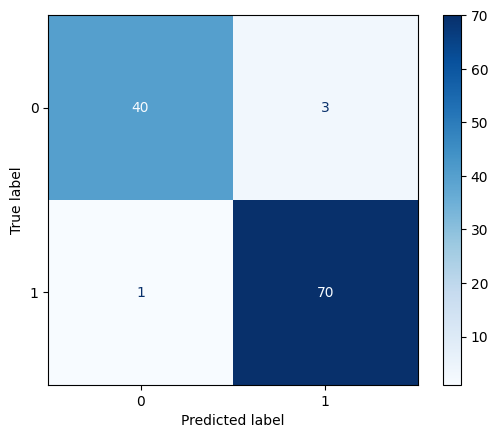

In [ ]:
data = load_breast_cancer()
X_np = data.data
y_np = data.target

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X_np, y_np, test_size=0.2, random_state=42
)

X_train = torch.tensor(X_train_np, dtype=torch.float32)
X_test  = torch.tensor(X_test_np, dtype=torch.float32)

y_train = torch.tensor(y_train_np, dtype=torch.float32).unsqueeze(1)
y_test  = torch.tensor(y_test_np, dtype=torch.float32).unsqueeze(1)

boosted_model2 = AdaBoostMultiKAN(n_estimators=5)
boosted_model2.fit()

auc_kan2, fpr2, tpr2 = boosted_model2.evaluate()

print(f"AdaBoost MultiKAN ROC-AUC: {auc_kan2:.4f}")

In [ ]:
losses_of_estimators

[[1,
  0.0016687196912243962,
  0.0016225660219788551,
  0.0015782910631969571,
  0.001535391784273088,
  0.0014943050919100642,
  0.0014556733658537269,
  0.001419911510311067,
  0.0013871733099222183,
  0.001357409404590726,
  0.0013304383028298616,
  0.0013060154160484672,
  0.0012838816037401557,
  0.0012637891341000795,
  0.0012455042451620102,
  0.0012288169236853719,
  0.0012135461438447237,
  0.001199518796056509,
  0.0011865600245073438,
  0.0011744779767468572,
  0.0011630661319941282,
  0.0011521166888996959,
  0.001141433254815638,
  0.00113084411714226,
  0.0011202170280739665,
  0.0011094703804701567,
  0.0010985733242705464,
  0.0010875443695113063,
  0.001076443470083177,
  0.0010653622448444366,
  0.0010544104734435678,
  0.0010436917655169964,
  0.0010332874953746796,
  0.0010232416680082679,
  0.001013550441712141,
  0.0010041635250672698,
  0.0009950039675459266,
  0.0009859954006969929,
  0.0009770841570571065,
  0.0009682484669610858,
  0.0009594961884431541,
  0.

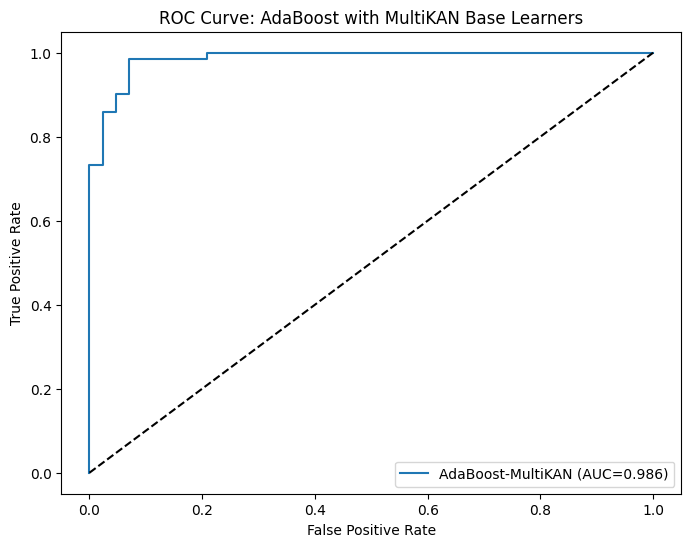

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(fpr2, tpr2, label=f"AdaBoost-MultiKAN (AUC={auc_kan2:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: AdaBoost with MultiKAN Base Learners")
plt.legend()
plt.show()


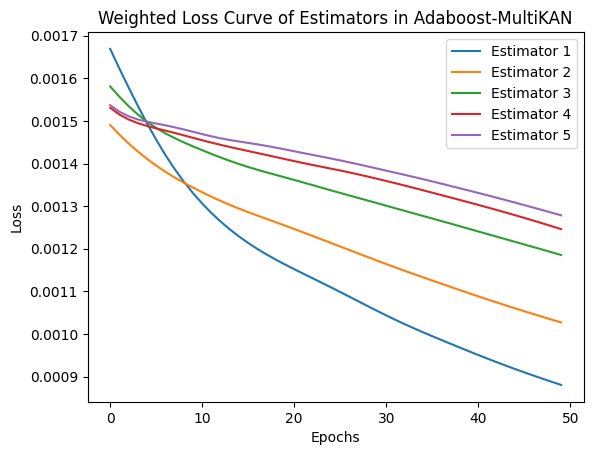

In [ ]:
plt.plot(losses_of_estimators[0][1:])
plt.plot(losses_of_estimators[1][1:])
plt.plot(losses_of_estimators[2][1:])
plt.plot(losses_of_estimators[3][1:])
plt.plot(losses_of_estimators[4][1:])
plt.title("Weighted Loss Curve of Estimators in Adaboost-MultiKAN")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Estimator 1", "Estimator 2", "Estimator 3", "Estimator 4", "Estimator 5"])
plt.show()

# Comparison of ROC-AUC curve between Adaboost-MLP and KAN with Adaboost

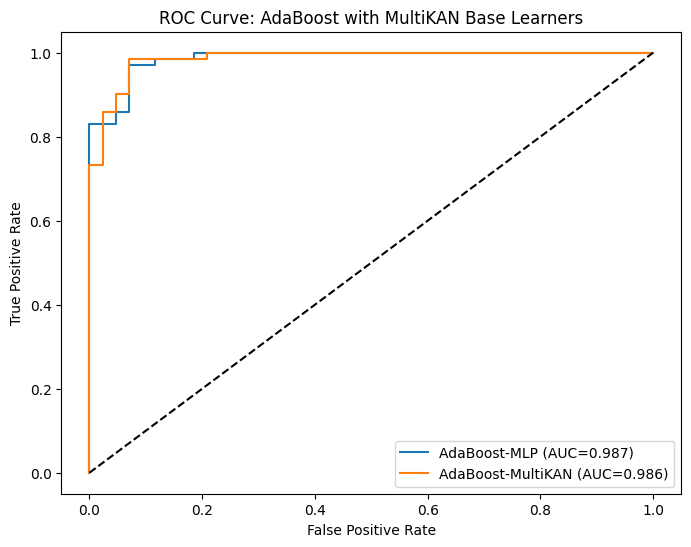

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AdaBoost-MLP (AUC={auc_kan:.3f})")
plt.plot(fpr2, tpr2, label=f"AdaBoost-MultiKAN (AUC={auc_kan2:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: AdaBoost with MultiKAN Base Learners")
plt.legend()
plt.show()